# Week 4 – Exploratory Data Analysis (EDA)

**Project:** Credit Card Fraud Detection

**Objective:** To perform Univariate and Bivariate Analysis to understand the distribution of transaction data and identify patterns between fraudulent and legitimate transactions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (284807, 31)


In [3]:
df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Shape after cleaning: (283726, 31)
Duplicate rows: 0


In [4]:
# Save cleaned dataset
df.to_csv("creditcard_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 1. Univariate Analysis

Univariate Analysis is the process of analysing a single variable at a time.

It helps us understand the distribution, frequency, central tendency and spread of individual variables.

In this project, we analyse transaction amount, transaction time and fraud class.

In [5]:
print(df[['Time', 'Amount']].describe())

                Time         Amount
count  283726.000000  283726.000000
mean    94811.077600      88.472687
std     47481.047891     250.399437
min         0.000000       0.000000
25%     54204.750000       5.600000
50%     84692.500000      22.000000
75%    139298.000000      77.510000
max    172792.000000   25691.160000


### 1.1 Transaction Amount Distribution

A histogram is used to understand the distribution of transaction amounts.

It helps identify whether transactions are concentrated around smaller or larger amounts.

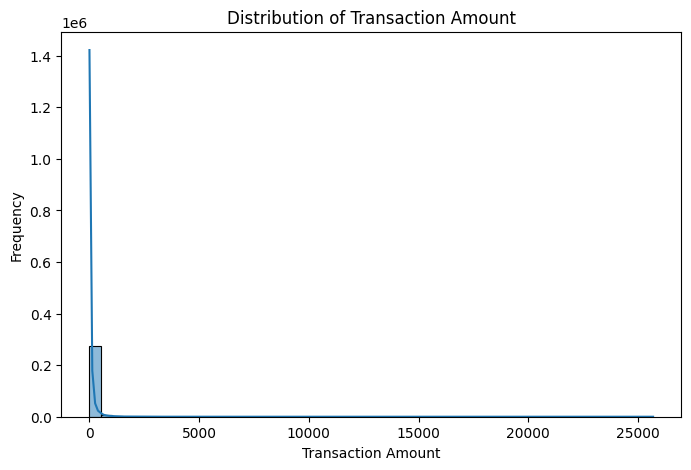

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Amount'], bins=50, kde=True)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

**Observation:**

The histogram helps identify the distribution of transaction amounts. It can reveal whether most transactions have smaller amounts and whether a few transactions have significantly larger amounts.

The distribution will be examined for skewness and extreme values.

### 1.2 Transaction Time Distribution

A histogram is used to understand the distribution of transaction times.

It helps identify how transactions are distributed throughout the recorded time period.

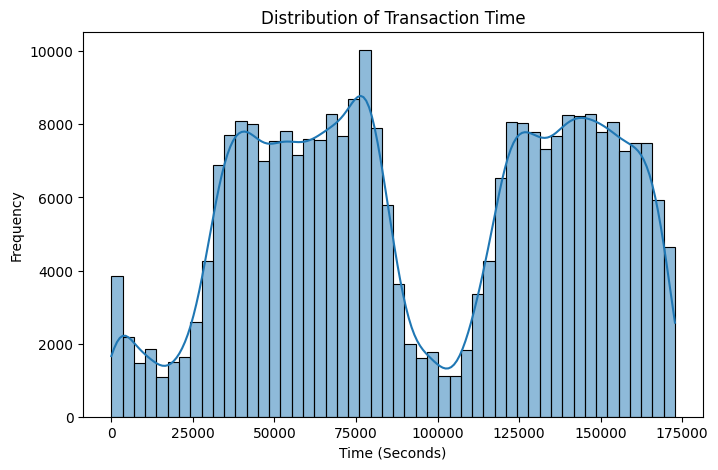

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Time'], bins=50, kde=True)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time (Seconds)")
plt.ylabel("Frequency")

plt.show()

**Observation:**

The histogram shows the distribution of transactions over time.

It helps identify periods with higher and lower transaction activity. The Time column represents seconds elapsed since the first transaction in the dataset, not the actual clock time.

### 1.3 Fraud Class Distribution

A count plot is used to analyse the number of legitimate and fraudulent transactions.

This helps identify class imbalance in the dataset.

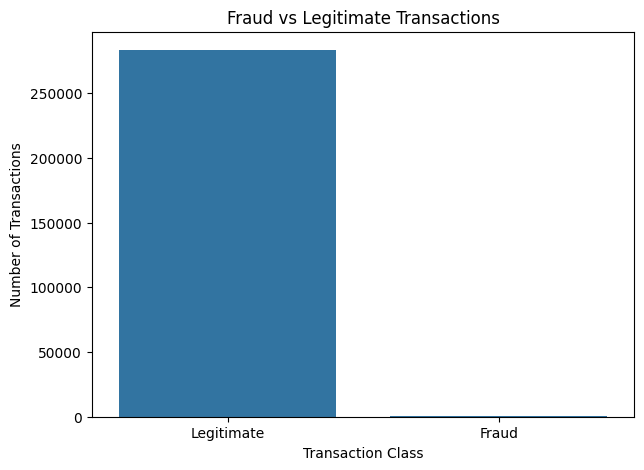

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(x='Class', data=df)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ['Legitimate', 'Fraud'])

plt.show()

In [9]:
class_counts = df['Class'].value_counts()

class_percentage = df['Class'].value_counts(normalize=True) * 100

print("Transaction Counts:")
print(class_counts)

print("\nTransaction Percentage:")
print(class_percentage)

Transaction Counts:
Class
0    283253
1       473
Name: count, dtype: int64

Transaction Percentage:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


**Observation:**

The dataset contains significantly more legitimate transactions than fraudulent transactions.

This indicates a highly imbalanced dataset. Fraudulent transactions represent only a very small percentage of the total transactions.

Class imbalance is an important factor to consider during further analysis and machine learning.

### 1.4 Distribution of V1 Feature

A histogram with KDE is used to understand the distribution of the V1 feature.

V1 is an anonymised feature obtained through Principal Component Analysis (PCA).

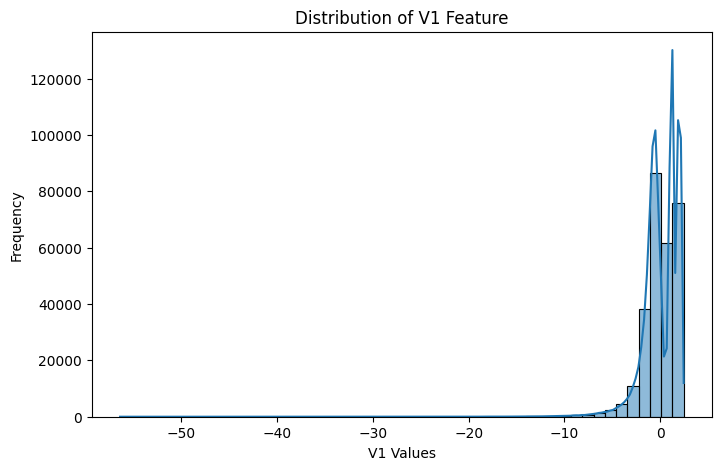

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(df['V1'], bins=50, kde=True)

plt.title("Distribution of V1 Feature")
plt.xlabel("V1 Values")
plt.ylabel("Frequency")

plt.show()

**Observation:**

The histogram shows the distribution and spread of the V1 feature.

It helps understand how frequently different V1 values occur and whether the distribution is symmetric or skewed.

## 2. Bivariate Analysis

Bivariate Analysis is the process of analysing two variables simultaneously.

It helps identify relationships, differences and patterns between two variables.

In this project, we compare transaction amount, transaction time and anonymised features with the fraud class.

### 2.1 Transaction Amount vs Fraud Class

A boxplot is used to compare transaction amounts between legitimate and fraudulent transactions.

It helps understand the distribution, median and spread of transaction amounts for both classes.

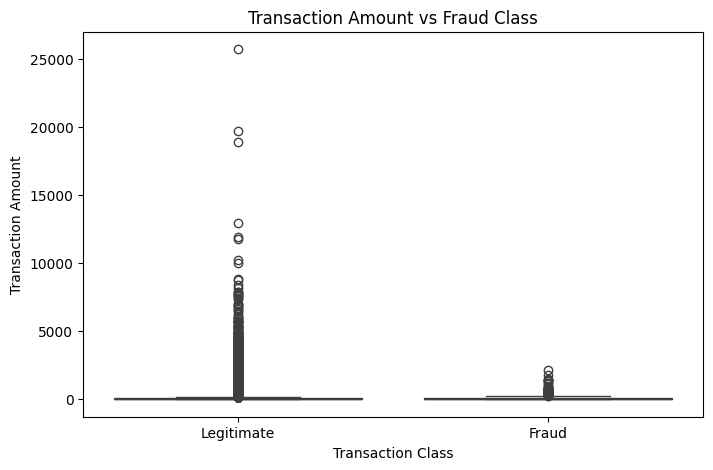

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Class', y='Amount', data=df)

plt.title("Transaction Amount vs Fraud Class")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")

plt.xticks([0, 1], ['Legitimate', 'Fraud'])

plt.show()

**Observation:**

The boxplot compares the transaction amount distributions of legitimate and fraudulent transactions.

It helps identify differences in median values, spread and potential outliers between the two classes.

The results can help us understand whether transaction amount is useful for identifying fraudulent activities.

### 2.2 Transaction Time vs Fraud Class

A boxplot is used to compare transaction times between legitimate and fraudulent transactions.

It helps identify differences in the time distribution of both transaction classes.

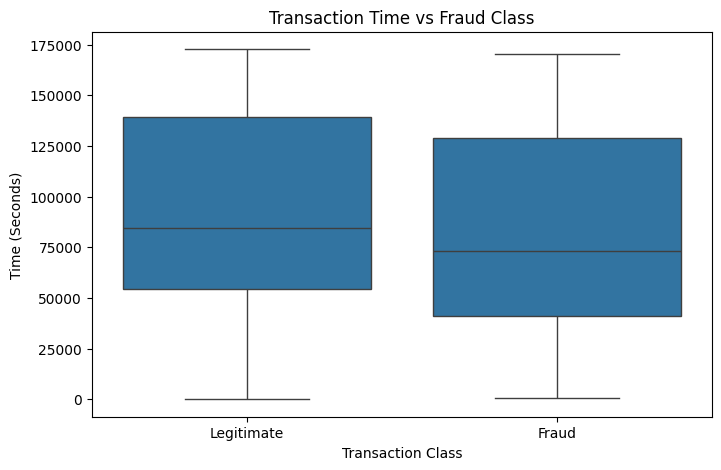

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Class', y='Time', data=df)

plt.title("Transaction Time vs Fraud Class")
plt.xlabel("Transaction Class")
plt.ylabel("Time (Seconds)")

plt.xticks([0, 1], ['Legitimate', 'Fraud'])

plt.show()

**Observation:**

The boxplot compares transaction time distributions between legitimate and fraudulent transactions.

It helps identify differences in median transaction time, spread and potential outliers.

This analysis helps investigate whether transaction timing has any relationship with fraudulent activities.

### 2.3 V1 Feature vs Fraud Class

A boxplot is used to compare V1 feature values between legitimate and fraudulent transactions.

It helps identify differences in the distribution of V1 values across both classes.

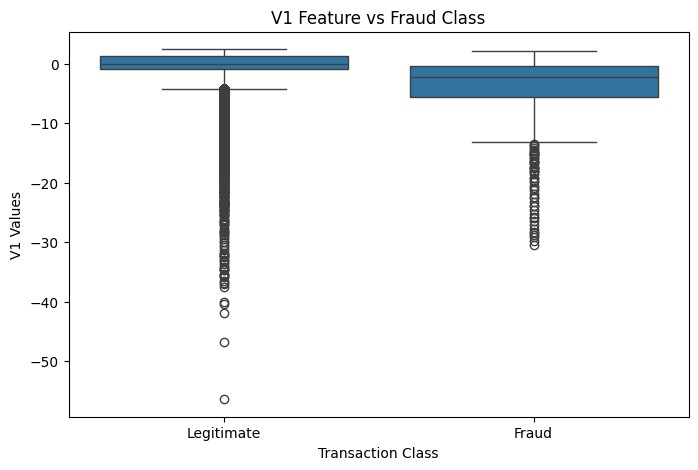

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Class', y='V1', data=df)

plt.title("V1 Feature vs Fraud Class")
plt.xlabel("Transaction Class")
plt.ylabel("V1 Values")

plt.xticks([0, 1], ['Legitimate', 'Fraud'])

plt.show()

**Observation:**

The boxplot compares V1 values between legitimate and fraudulent transactions.

Differences in median values and distributions may indicate that the V1 feature contains useful information for distinguishing fraudulent transactions.

### 2.4 Relationship Between V1 and V2

A scatter plot is used to analyse the relationship between V1 and V2.

The fraud class is represented using different colours to identify patterns between legitimate and fraudulent transactions.

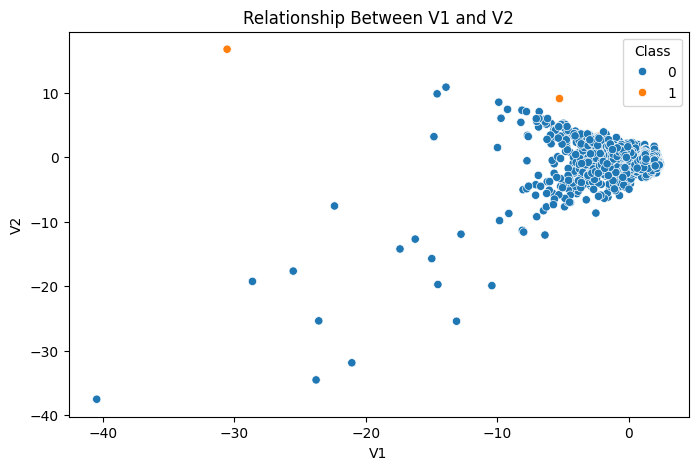

In [14]:
sample_df = df.sample(5000, random_state=42)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sample_df,
    x='V1',
    y='V2',
    hue='Class'
)

plt.title("Relationship Between V1 and V2")
plt.xlabel("V1")
plt.ylabel("V2")

plt.show()

**Observation:**

The scatter plot visualises the relationship between V1 and V2.

Different colours represent legitimate and fraudulent transactions.

It helps identify whether fraudulent transactions form any distinct patterns or clusters compared with legitimate transactions.

## 3. Correlation Analysis

Correlation analysis is used to measure the relationship between numerical variables.

It helps identify positively correlated, negatively correlated and weakly correlated features.

A correlation heatmap is used to visualise these relationships.

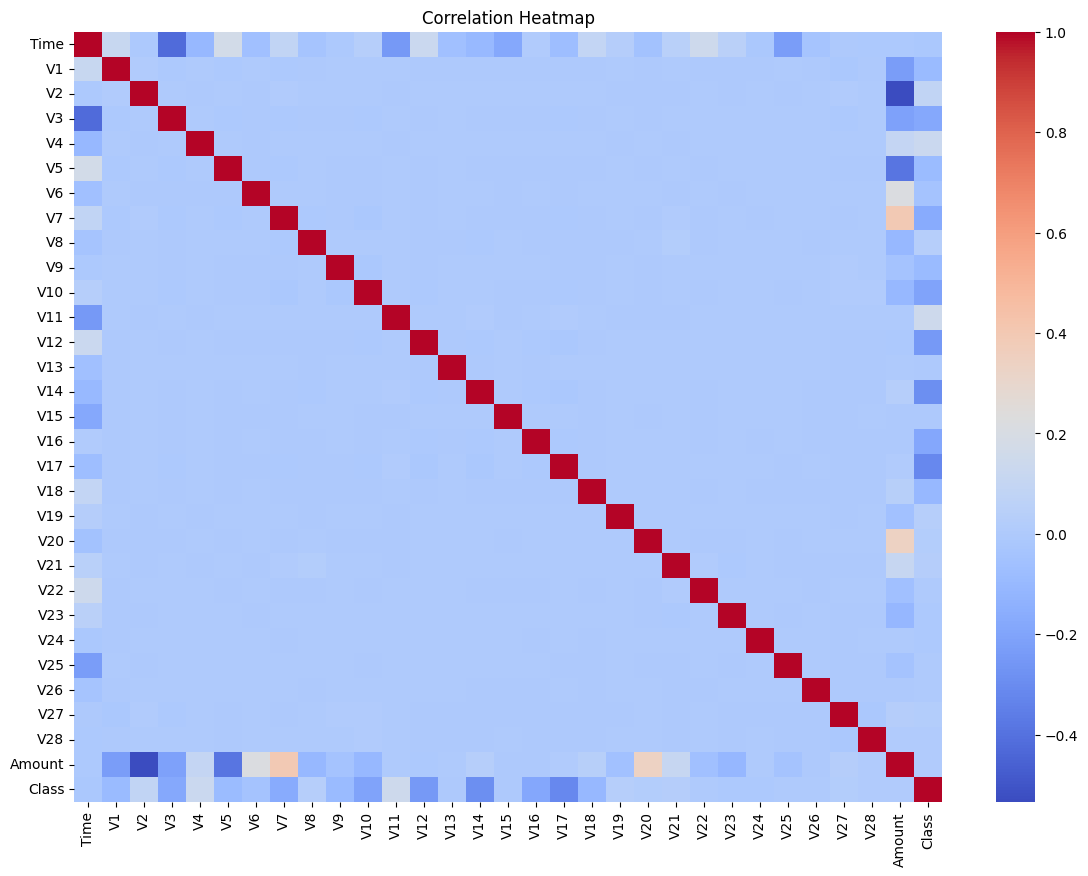

In [15]:
plt.figure(figsize=(14, 10))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False
)

plt.title("Correlation Heatmap")

plt.show()

**Observation:**

The correlation heatmap represents relationships between numerical features using colour intensity.

Positive correlation indicates that two variables tend to increase together, while negative correlation indicates that one variable tends to decrease when the other increases.

This analysis provides an overview of relationships among the dataset features.

# Week 4 – Conclusion

Exploratory Data Analysis was performed on the Credit Card Fraud Detection dataset.

Univariate Analysis was used to study individual variables such as transaction amount, transaction time, fraud class and the V1 feature.

Bivariate Analysis was performed to understand the relationships between transaction amount, transaction time, anonymised features and fraud class.

Histograms, count plots, boxplots and scatter plots were used to visualise the data distributions and identify patterns.

The analysis also highlighted the class imbalance in the dataset, where fraudulent transactions represent a very small proportion of the total transactions.

Correlation analysis was performed to understand relationships between numerical features.

The findings from this analysis will be useful for further statistical analysis, feature engineering and dimensionality reduction in the upcoming weeks.